C:\Users\shrey\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.0.post2)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,316 (87.17 KB)

 Trainable params: 22,316 (87.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.7951 - mae: 0.6006 
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4346 - mae: 0.4155 
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2981 - mae: 0.3354 
Epoch 4/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2316 - mae: 0.2923 
Epoch 5/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1936 - mae: 0.2673 
Epoch 6/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1651 - mae: 0.2482 
Epoch 7/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1442 - mae: 0.2346 
Epoch 8/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1291 - mae: 0.2231 
Epoch 9/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1177 - mae: 0.2138 
Epoch 10/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1086 - mae: 0.2064 
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Threshold: 0.3006339966551229
              precision    recall  f1-score   support

         0.0       0.81      0.95 

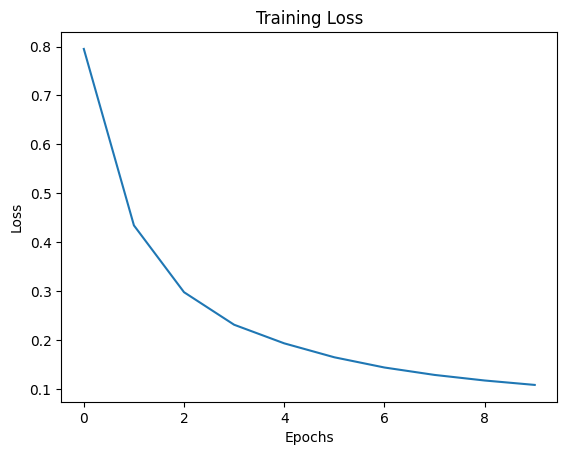

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

# Load dataset
data = pd.read_csv("ecg.csv", header=None)

x = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

# Split dataset
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

# Normalize data using normal training records
scaler = StandardScaler()
scaler.fit(x_train[y_train == 0])

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

# Keep only normal records for training
x_train = x_train[y_train == 0]

# Build Autoencoder
model = Sequential([
    Input(shape=(140,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),
    Dense(140, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

# Train model
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32
)

# Calculate training reconstruction error
train_pred = model.predict(x_train)

train_error = np.mean(
    (x_train - train_pred) ** 2,
    axis=1
)

threshold = np.percentile(train_error, 95)

# Calculate testing reconstruction error
test_pred = model.predict(x_test)

test_error = np.mean(
    (x_test - test_pred) ** 2,
    axis=1
)

# Detect anomalies
y_pred = (test_error > threshold).astype(int)

print("Threshold:", threshold)
print(classification_report(y_test, y_pred))

# Plot loss
plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()